In [1]:
"""
<군집(Clustering) 분석>
 - 비지도 학습 방법 : 정답(target) 데이터 없이 분류하는 방법
 - 독립변수만 존재하고, 종속변수는 존재하지 않는 경우를 -> 비지도 학습이라고 합니다.
 - 데이터 유형 : 비정형 데이터
 - 데이터 유형 종류 : 행렬로 정제되지 않은 데이터
 - 군집분석 : 패턴이 유사한 데이터들 간에 묶는(분류) 작업을 수행합니다.
 - 묶음 단위를 군집(Clustering)이라고 칭합니다.
 - 대표 모델 : KMeans(K평균) 모델, DBSCAN 모델
 - 평가 방법 : Silhouette Score, adjusted rand Score
"""

'\n<군집(Clustering) 분석>\n - 비지도 학습 방법 : 정답(target) 데이터 없이 분류하는 방법\n - 독립변수만 존재하고, 종속변수는 존재하지 않는 경우를 -> 비지도 학습이라고 합니다.\n - 데이터 유형 : 비정형 데이터\n - 데이터 유형 종류 : 행렬로 정제되지 않은 데이터\n - 군집분석 : 패턴이 유사한 데이터들 간에 묶는(분류) 작업을 수행합니다.\n - 묶음 단위를 군집(Clustering)이라고 칭합니다.\n - 대표 모델 : KMeans(K평균) 모델, DBSCAN 모델\n - 평가 방법 : Silhouette Score, adjusted rand Score\n'

### KMeans 모델

In [2]:
"""
<KMeans 모델>
 - "미리 정의된 K개의 클러스터(군집)"로 나누는 군집화 모델
 - K의 값은 클러스터(군집)의 갯수를 의미하며,
   모델 생성시 정의해야 합니다.(하이퍼파라메터 튜닝이 일어나는 변수)
 - 각 클러스터는 중심이라고 불리는 점을 가집니다.(중앙 포인트, 중심점)
 - 독립변수들은 중심점과의 거리를 기준으로 가까운 곳의 클러스터로 속하게(분류되게) 됩니다.
 - 새로 포함된 데이터들을 포함하여 중심점을 계산하면서 변경해 나갑니다.
 - 더 이상 변경이 필요없을 때까지 분류를 하게 됩니다.(모델이 알아서 합니다.)
 
 (군집 순서)
  1. 임의 K개 초기화 중심점 갯수 지정
  2. 각 독립변수의 데이터를 중심점과 가까운 곳에 형성
  3. 각 클러스터의 중심점 재계산
  4. 중심점이 더 이상 변하지 않거나, 더 이상 군집이 필요하지 않을 때 까지
     2~3번의 작업을 반복 수행 합니다.
     
 (특징)
  - 군집 갯수 사전 설정 해야함
  - 원형 형태로 군집을 형성함
  - 대규모 데이터에 효율적임 : 계산이 비교적 빠름(타 모델에 비해)
"""

'\n<KMeans 모델>\n - "미리 정의된 K개의 클러스터(군집)"로 나누는 군집화 모델\n - K의 값은 클러스터(군집)의 갯수를 의미하며,\n   모델 생성시 정의해야 합니다.(하이퍼파라메터 튜닝이 일어나는 변수)\n - 각 클러스터는 중심이라고 불리는 점을 가집니다.(중앙 포인트, 중심점)\n - 독립변수들은 중심점과의 거리를 기준으로 가까운 곳의 클러스터로 속하게(분류되게) 됩니다.\n - 새로 포함된 데이터들을 포함하여 중심점을 계산하면서 변경해 나갑니다.\n - 더 이상 변경이 필요없을 때까지 분류를 하게 됩니다.(모델이 알아서 합니다.)\n \n (군집 순서)\n  1. 임의 K개 초기화 중심점 갯수 지정\n  2. 각 독립변수의 데이터를 중심점과 가까운 곳에 형성\n  3. 각 클러스터의 중심점 재계산\n  4. 중심점이 더 이상 변하지 않거나, 더 이상 군집이 필요하지 않을 때 까지\n     2~3번의 작업을 반복 수행 합니다.\n     \n (특징)\n  - 군집 갯수 사전 설정 해야함\n  - 원형 형태로 군집을 형성함\n  - 대규모 데이터에 효율적임 : 계산이 비교적 빠름(타 모델에 비해)\n'

### 사용할 라이브러리 불러들이기

In [3]:
### 사용할 라이브러리 불러들이기
# 데이터 조작을 위한 라이브러리
import pandas as pd

# 기본 시각화 라이브러리
import matplotlib.pyplot as plt

# 통계적 시각화 라이브러리(보통 기본 시각화보다 향상된 라이브러라고 생각하면 됨)
import seaborn as sns

# 시각화 시 그래프의 너비/높이를 기본 설정하기(단위=인치)
plt.rcParams["figure.figsize"] = (12, 5)

# 시각화시 한글 깨짐 처리를 위한 폰트 지정(Windows OS 기준)
plt.rcParams["font.family"] = "Malgun Gothic"

# 시각화시 마이너스(-) 기호 깨짐 방지 처리
plt.rcParams["axes.unicode_minus"] = False


### 데이터스케일링
from sklearn.preprocessing import StandardScaler

### 훈련:테스트 데이터 분리
from sklearn.model_selection import train_test_split

### 군집 모델
from sklearn.cluster import KMeans, DBSCAN

### 튜닝 클래스
from sklearn.model_selection import GridSearchCV

### 지도-분류분석 평가
from sklearn.metrics import accuracy_score, confusion_matrix

### 군집분석 평가
from sklearn.metrics import silhouette_score, adjusted_rand_score

### 데이터 읽어 들이기

In [4]:
### data폴더의 와인 데이터 읽어들이기
# - 변수명 : data
file_path = "./data/08_wine.csv"
data = pd.read_csv(file_path)

data.info()
display(data.describe())
data.head(1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6497 non-null   float64
 2   pH       6497 non-null   float64
 3   class    6497 non-null   float64
dtypes: float64(4)
memory usage: 203.2 KB


,alcohol,sugar,pH,class
count,6497.000000,6497.000000,6497.000000,6497.000000
mean,10.491801,5.443235,3.218501,0.753886
std,1.192712,4.757804,0.160787,0.430779
min,8.000000,0.600000,2.720000,0.000000
25%,9.500000,1.800000,3.110000,1.000000
50%,10.300000,3.000000,3.210000,1.000000
75%,11.300000,8.100000,3.320000,1.000000
max,14.900000,65.800000,4.010000,1.000000


,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0


### 훈련에 사용할 데이터(독립변수, 종속변수)로 분리하기

In [30]:
### 1. 독립변수/종속변수 분리하기 (numpy 리스트 타입으로 처리)
# 변수명 : X(독립변수), y(종속변수) 사용
X = data[["alcohol", "sugar", "pH"]].to_numpy()
y = data["class"].to_numpy()

X.shape, y.shape

((6497, 3), (6497,))

### 데이터스케일링 처리하기

In [32]:
### Standard만 처리
# 변수명 : X_scaler
ss = StandardScaler()
X_scaler = ss.fit_transform(X)

print(X_scaler.shape, y.shape)
print(X_scaler)

(6497, 3) (6497,)
[[-0.91546416 -0.7447781   1.81308951]
 [-0.58006813 -0.59764007 -0.11507303]
 [-0.58006813 -0.66069923  0.25811972]
 ...
 [-0.91546416 -0.89191614 -1.42124765]
 [ 1.9354021  -0.91293585  0.75571005]
 [ 1.09691202 -0.97599501  0.25811972]]


### 훈련 : 테스트 = 8 : 2로 분리

In [33]:
### 변수명 : X_train, y_train, X_test, y_test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaler, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(5197, 3) (5197,)
(1300, 3) (1300,)


### 하이퍼파라메터 튜닝 모델 사용

In [34]:
##### KMeans에서 사용하는 하이퍼파라메터들...

### 하이퍼파라메터를 담을 딕셔너리 타입의 변수 정의
param_grid = {}

### 군집시 사용할 중심정 이동 횟수 설정
# - 초기 중심점에서 시작하여 -> 중심점을 재정의(중심점 이동) 횟수를 정의
param_grid["n_init"] = [10, 30, 50]

### 최대 훈련 반복횟수 정의
param_grid["max_iter"] = [10, 30, 50]

### 모델 훈련 시 학습 정확도가 설정값보다 작으면 훈련 종료 시키기 위한 값 설정
param_grid["tol"] = [0.0001, 0.001, 0.01, 1]

### 튜닝 모델 교차검증을 위한 폴드 갯수 정의
cv = 5

### 튜닝 모델 평가 기준
scoring = "accuracy"

### KMeans 군집의 갯수 정의
# - 종속변수의 범주 갯수로 예상되는 갯수(군집 갯수)를 의미함
# - 예상되는 군집의 갯수(종속변수 범주의 갯수)를 모를 경우 2부터 시작...
n_cluster = 2

param_grid

{'n_init': [10, 30, 50],
 'max_iter': [10, 30, 50],
 'tol': [0.0001, 0.001, 0.01, 1]}

### 훈련에 사용할 실제 모델(KMeans) 생성하기

In [35]:
kmeans = KMeans(n_clusters = n_cluster, random_state=42)
kmeans

,n_clusters,2
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [37]:
### 하이퍼파라메터 튜닝 클래스 생성하기
grid_search = GridSearchCV(
    estimator = kmeans,
    param_grid = param_grid,
    cv = cv,
    scoring = scoring
)
grid_search

,estimator,KMeans(n_clus...ndom_state=42)
,param_grid,"{'max_iter': [10, 30, ...], 'n_init': [10, 30, ...], 'tol': [0.0001, 0.001, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_clusters,2


In [38]:
### 최적의 하이퍼파라메터를 찾기위한 실제 모델로 훈련 시키기
# - 튜닝 클래스를 이용하여 fit()할 경우에는 무조건 (독립변수와 종속변수)를 함께 사용해야 합니다.
# - 튜닝 클래스는 지도학습(정답을 알고 있는 상태) 기반에서 사용됩니다.
grid_search.fit(X_train, y_train)

,estimator,KMeans(n_clus...ndom_state=42)
,param_grid,"{'max_iter': [10, 30, ...], 'n_init': [10, 30, ...], 'tol': [0.0001, 0.001, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_clusters,2


In [39]:
### 최적의 best 모델 추출하기
best_model = grid_search.best_estimator_
best_model

,n_clusters,2
,init,'k-means++'
,n_init,50
,max_iter,10
,tol,0.01
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


### 지도학습 분류분석 방식으로 평가하기

In [43]:
### 테스트 데이터로 -> 정확도와 오차행렬표 확인해주세요.

# - 테스트 데이터로 예측하기
test_pred = best_model.predict(X_test)
print(test_pred)

# - 정확도 확인하기
test_acc = accuracy_score(y_test, test_pred)
print(test_acc)

# - 오차행렬표 추출하기
cm = confusion_matrix(y_test, test_pred)
cm


[1 1 0 ... 1 1 0]
0.4453846153846154


array([[  6, 314],
       [407, 573]])

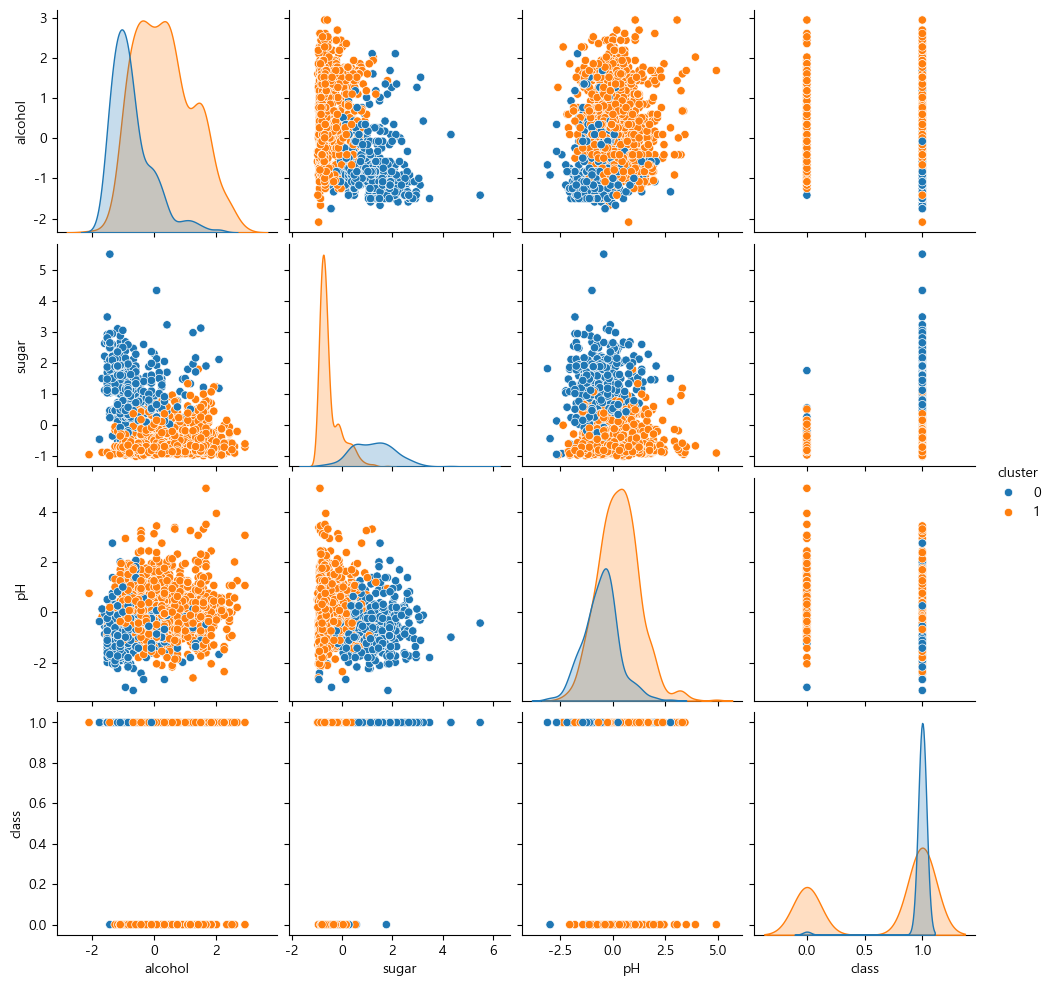

In [ ]:
### 클러스터 결과를 이용해서 산점행렬도 시각화하기

# - 산점행렬도에 사용할 데이터프레임 가공하기
data_view = {
    "alcohol" : X_test[:, 0],
    "sugar"   : X_test[:, 1],
    "pH"      : X_test[:, 2],
    "class"   : y_test,
    "cluster" : test_pred
}
test_data = pd.DataFrame(data = data_view)
test_data.head(5)

### 산점행렬도 시각화하기
# sns.pairplot(test_data)

# - cluster 데이터의 [범주]를 기준으로 분포 표시하기(hue 사용하기)
sns.pairplot(test_data, hue="cluster")
plt.show()

### (해석)
# - 군집이 잘 되었다면, 색이 완전히 분리되어 보이게됨.
# - 색이 겹치거나, 섞여 있다는 의미는 군집(분리)가 잘 안된 것임(빈도 그래프(중앙 대각선)만으로도 해석가능)

### IRIS 꽃잎 데이터로 군집분석하기

In [49]:
### iris 데이터셋 읽어들이기
# - iris 데이터셋 제공 패키지
#    : sklearn.datasets
#    : load_iris() 함수 사용
from sklearn.datasets import load_iris

### 전체 타입은 딕셔너리 타입으로 제공됨
# - 데이터는 numpy의 배열-array(리스트) 타입으로 제공됨
# - data(2차원 독립변수), target(1차원 종속변수),  
#   feature_names(각 컬럼의 이름), target_names(종속변수 범주들의 이름)
iris = load_iris()
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [50]:
### 독립변수(X)와 종속변수(y)로 데이터 추출하기
X = iris["data"]
y = iris["target"]

print(X.shape, y.shape)
X, y

(150, 4) (150,)


(array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
        [5

In [51]:
### KMeans 모델 생성하기
# - 군집 갯수 : 3
# - 중심점 이동 횟수 : 10회
# - 랜덤규칙 : 42
# - 모델 변수명 : kmeans_model
kmeans_model = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_model

,n_clusters,3
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [52]:
### 훈련 시키기
# - 군집분석에서는 독립변수만 사용됨
#   (비지도 학습이므로, 종속변수는 없다고 생각하면 됩니다.)
kmeans_model.fit(X)

,n_clusters,3
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [54]:
### 예측하기(X 데이터로 예측)
# 변수명: kmeans_labels
kmeans_labels = kmeans_model.predict(X)
print(kmeans_labels)
print(y)

"""
 - 모델이 예측한 종속변수(군집결과)는 실제 종속변수(군집결과)의
   순서와 무관합니다.
 - 모델이 예측한 군집 결과는 모델이 스스로 만들어낸 군집 번호일 뿐입니다.
 
 - 실제 범주 0 -> 군집 1로 분류됨
   실제 범주 1 -> 군집 0으로 분류됨
   실제 범주 2 -> 군집 2로 분류됨
"""

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


### 군집의 분포를 산점도 시각화 하기

In [ ]:
"""
 - 군집 분포를 시각화할 때 사용하는 그래프 : 산점도(scatter) 사용
 - 시각화시 사용하는 방법 : 주성분분석(PCA)을 통한 결과값으로 시각화를 주로 함

 <주성분(PCA) 분석>
    - 훈련에 사용된 특성들 중에 ["특징을 가장 잘 나타낼 수 있는 특성들을 추출"]하는 방법
    - 특징을 잘 나타내는 특성을 추출하여, 특성들을 축소 시키는 방식으로 사용됨
      --> 이를 "차원 축소(특성을 줄인다는 의미)"라고 칭합니다.
    - 주요 특징을 가지는 특성들만을 추출하여 사용하는 방식을 주성분 분석이라고 칭합니다.
    - 데이터가 매우 많은 경우에 유리합니다.
    - 데이터의 특성을 추출하여, 차원을 줄이는 방식을 사용하기에
       -> 빠른 처리가 가능합니다.

    - 사용 패키지 : sklearn.decomposition
    - 사용 모델(클래스, 변환기) : PCA
"""

In [55]:
from sklearn.decomposition import PCA

In [58]:
### 시각화(x축, y축)를 위해 2개의 주성분으로 압축하기
### 주성분(차원축소) 분석 클래스(모델, 변환기) 생성하기
# - 생성시에 축소할 차원을 정의해야 합니다.
# - n_components : 축소할 차원 정의
# - 시각화를 위해서는 x축, y축의 2차원 데이터가 필요하기 때문에
#   -> 차원을 2차원으로 축소(독립변수가 해당됨)
#   -> 이때 차원의 의미는 특성(컬럼)의 갯수를 의미합니다.

pca = PCA(n_components=2)
pca

### 주성분 패턴 찾기
pca.fit(X)

### 찾은 주성분 패턴으로 독립변수 변환시키기
# - 변수명 : X_pca
X_pca = pca.transform(X)

X.shape, X_pca.shape, y.shape

((150, 4), (150, 2), (150,))

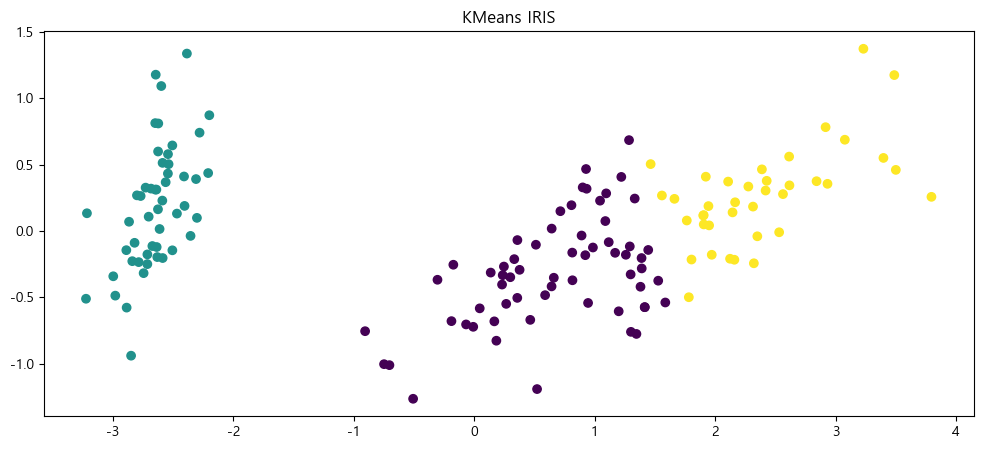

In [59]:
### 산점도 그리기
plt.title("KMeans IRIS")
# - kmeans_labels : 예측(군집) 결과값
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels)
plt.show()

"""
<군집이 잘되었는지 안되었는지 확인 방법>
 - 군집 간의 거리로 확인합니다.
 - 군집 간의 거리가 멀수록 잘된 군집
 - 군집 간의 거리가 가까울 수록 군집이 잘 안됨(간섭이 있다는 의미)
"""

### 군집분석 평가하기

In [ ]:
"""
<평가 방법>
1. silhouette_score(실루엣 평가)
    <개념>
     - 클러스터링 결과의 품질을 평가하는 지표로,
     - 데이터 포인트가 자신의 클러스터 내에 ["잘 속해"] 있는지와
     - 다른 클러스터와 ["잘 분리"]되어 있는지를 측정
   
     - 점수는 -1에서 1 사이이며:
       * 1에 가까울수록: 잘 분리된 클러스터
         (군집 내부 응집도가 높고, 군집 간 분리가 잘 됨).
       * 0에 가까울수록: 군집이 겹치거나 경계가 불분명함.
       * -1에 가까울수록: 데이터가 잘못된 군집에 속해 있음.
   
     - 군집의 응집도와 분리도를 평가
     - 사용 상황: 클러스터링 결과를 비교할 때 사용.
     - 클러스터링에 사용될 데이터만 있으면 됨(비지도 학습)

2. adjusted_rand_score
    <개념>
     - 클러스터링 결과와 ["정답 레이블(Ground Truth, 종속변수==정답)"]을 비교하여,
     - 클러스터링 결과의 ["정확성을 평가"]하는 지표
     - "종속변수가 없으면 평가할 수 없음"
   
     - 점수는 -1에서 1 사이이며:
       * 1: 완벽하게 정답과 일치(군집화 잘됨)
       * 0: 정답과 불일치가 많음 -> 군집화가 잘 안됨
       * 음수: 군집화 결과가 정답과 상반되는 구조(군집화 안좋음)
   
     - 군집 결과와 ["정답"]의 유사도를 평가
     - 사용 상황: 클러스터링 결과를 비교할 때 사용.
     - 클러스터링에 사용될 데이터와 정답 데이터만 있으면 됨
       (비지도 학습이지만, "평가는 정답으로 진행")

 - 사용 패키지 : sklearn.metrics
 - 사용 평가 함수 : silhouette_score, adjusted_rand_score
"""

In [60]:
### silhouette_score(독립변수, 예측(군집)결과)
s_score = silhouette_score(X, kmeans_labels)
s_score

### 0.5 이상이면 군집이 어느정도는 잘 되었다고 판단 가능(보통 0.7 이상이면 잘 되었다고 볼 수 있음)

0.5528190123564095

In [62]:
### adjusted_rand_score(실제종속변수, 예측(군집)결과)
a_score = adjusted_rand_score(y, kmeans_labels)
a_score

0.7302382722834697

### DBSCAN 모델 사용하기

In [ ]:
"""
<DBSCAN 모델>
 - DBSCAN(Density-Based Spatial Clustering of Applications with Noise)
 - "밀도 기반의 군집화 모델"
 - 데이터 포인터(위치)의 밀도(분포된 형태)를 기준으로 클러스터를 형성
 - 밀도가 높은 영역은 클러스터로 포함,
 - 밀도가 낮은 영역은 노이즈(이상치)로 간주하여 클러스터에 포함시키지 않음
   (이런 경우 군집번호, 즉 레이블 값은 -1값이 나옵니다.)
 - 최초 군집의 갯수를 정하지 않음(군집의 갯수를 모를 때 사용)
   
 (군집순서)
  1. 각 데이터 포인트에 대해 주변 반경(거리) 내의 이웃 데이터 포인트 수를 계산
  2. 이 이웃의 수가 설정된 최소 샘플 수(min_samples)를 충족하면,
     해당 포인트를 핵심 포인트로 간주하여 클러스터에 포함
  3. 클러스터에 속하지 않는 포인트는 노이즈(이상치)로 분류

 (특징)
  - 자동으로 군집 갯수 결정 : 미리 클러스터의 갯수를 지정할 필요 없음
  - 비원형 클러스터 형태를 띔
  - 노이즈 처리 됨 : 클러스터에 포함되지 않은 데이터들이 발생함
  - 데이터가 많은(행/열) 경우 비 효율적임 : 속도가 다소 느릴 수 있음

 (사용 라이브러리)
  - 사용 패키지 : sklearn.cluster
  - 사용 모델(클래스) : DBSCAN
  - 평가 방법은 KMeans와 동일
"""

In [63]:
### 모델 생성하기
"""
<DBSCAN 클래스 속성>
 * eps(epsilon) : 거리반경
  - 특정(임의) 데이터 포인트를 중심으로,
  - 그 주변에 있는 데이터 포인트들을 이웃(neighbor)으로 간주하는 최대 거리를 설정함
 
 * min_samples : 최소 샘플 수(클러스터 밀도라고도 칭함)
  - 하나의 클러스터를 형성하기 위해 eps 거리 내에 존재해야 하는
    최소 데이터 포인트(데이터) 수를 의미함
"""

dbscan = DBSCAN(eps=0.5, min_samples=5)
dbscan

,eps,0.5
,min_samples,5
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


In [ ]:
### 훈련시키기
### 예측하기
### DBSCAN 모델은 훈련과 동시에 예측이 진행되는 함수를 사용.
# - 변수명 : clusters
clusters = dbscan.fit_predict(X)
print(clusters)

### 군집결과
# - 군집은 2개로 분류됨(0과 1로)
# - 군집이 되지 않은 노이즈(이상치)는 -1로...


[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1  1 -1  1  1 -1  1  1  1  1  1  1  1 -1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1 -1  1  1
  1  1 -1  1  1  1  1  1  1 -1 -1  1 -1 -1  1  1  1  1  1  1  1 -1 -1  1
  1  1 -1  1  1  1  1  1  1  1  1 -1  1  1 -1 -1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1]


### 노이즈(이상치) 제거하기

In [78]:
### 노이즈(-1)에 대한 데이터 모두 제거하기
# - 독립변수(X)와 예측결과(clusters)에서 모두 제거하기

# - 노이즈가 있는 인덱스 위치 추출하기
print(X.shape, clusters.shape)
X, clusters

### clusters의 리스트 데이터 중에 -1인 것 : 필터링
# - 결과값은 리스트로 : 값은 -1인것은 True로, 아닌것은 False로 반환됨
noise = clusters == -1
# print(noise)

# - 노이즈 제거 후 독립변수명 : X_cleaned
#  : noise의 값이 False인 위치(인덱스 위치)의 값만 X 데이터에서 추출
X_cleaned = X[noise == False]
print(X_cleaned.shape)

# - 노이즈 제거 후 예측결과 변수명 : clusters_cleaned
#  : noise의 값이 False인 위치(인덱스 위치)의 값만 clusters 데이터에서 추출
clusters_cleaned = clusters[noise == False]
print(clusters_cleaned.shape)
print(clusters_cleaned)

(150, 4) (150,)
(133, 4)
(133,)
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


### 시각화를 위해 주성분(PCA) 분석하기

In [81]:
### 시각화시 X축과 Y축에 표시된 데이터 2개로 압축하기

# - 주성분 클래스 생성
pca = PCA(n_components=2)
pca

# - 패턴찾기
pca.fit(X)

# - 변환시키기
# - 노이즈 제거전 데이터 변환하기(시각화로 표시해 보려고..)
X_pca_org = pca.transform(X)

# - 노이즈 제거후 데이터 변환하기
X_pca_cleaned = pca.transform(X_cleaned)

X_pca_org.shape, X_pca_cleaned.shape

((150, 2), (133, 2))

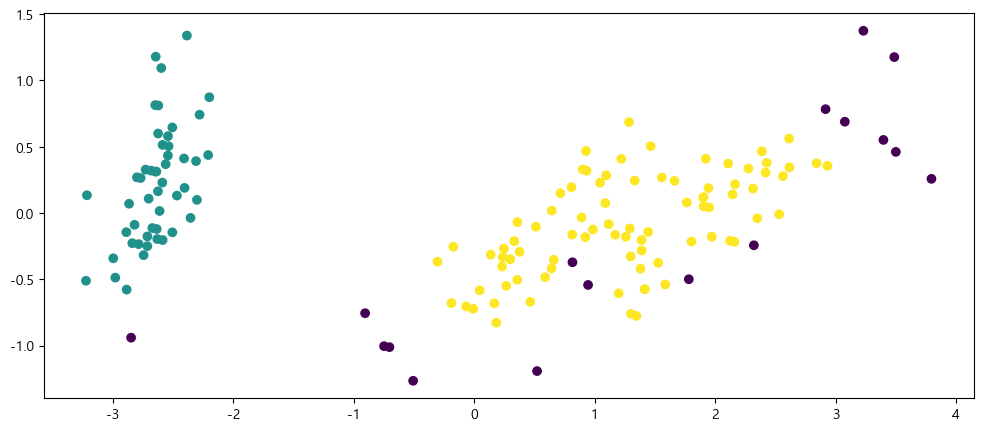

In [82]:
### 노이즈 제거 전 데이터 시각화
plt.scatter(X_pca_org[:, 0], X_pca_org[:, 1], c=clusters)
plt.show()

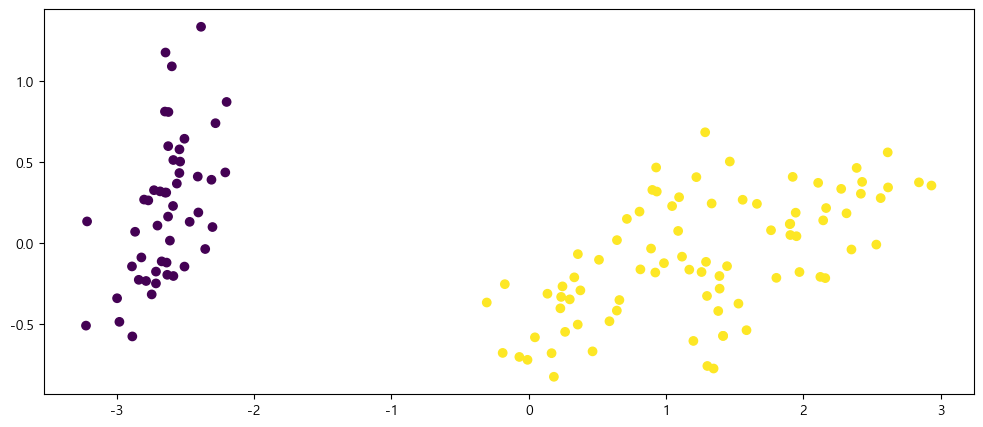

In [83]:
### 노이즈 제거 후 데이터 시각화
plt.scatter(X_pca_cleaned[:, 0], X_pca_cleaned[:, 1], c=clusters_cleaned)
plt.show()

### 군집분석 평가하기

In [84]:
### silhouette_score(독립변수, 예측결과) 평가
# - 노이즈 제거 전 평가
noise_ok = silhouette_score(X, clusters)

# - 노이즈 제거 후 평가
noise_no = silhouette_score(X_cleaned, clusters_cleaned)

noise_ok, noise_no


(0.48603419703456857, 0.7353564754798495)

In [85]:
### adjusted_rand_score(종속변수, 예측결과) 평가
# - 노이즈 제거 전 평가
noise_ok = adjusted_rand_score(y, clusters)

# - 노이즈 제거 후 평가
noise_no = adjusted_rand_score(y[noise == False], clusters_cleaned)

noise_ok, noise_no

(0.5206185241703302, 0.6072737211626338)

In [86]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [ ]:
"""
(해석)
 - KMeans 모델의 경우 추정 군집의 갯수로 어느정도 군집이 가능하지만,
 - DBSCAN 모델의 경우에는 실제 3개의 군집으로 분류하기에는 어려움이 있음
"""